# 01 - Exploratory analysis

Descriptive and diagnostic analytics for the study districts. All numbers are produced by `make analytics-eda` from the PostgreSQL warehouse; this notebook only displays them. Check the data-status banner first.

In [1]:
from pathlib import Path
import pandas as pd
from IPython.display import Image, Markdown, display
pd.set_option('display.width', 200)
ROOT = Path.cwd()
findings = (ROOT / 'docs' / 'FINDINGS.md').read_text(encoding='utf-8')
display(Markdown(findings))

# Findings: climate, weather and crop yield in the study districts

> **SYNTHETIC DATA IN USE: `satellite_16d` (100% synthetic).** Findings that depend on these tables are flagged below.
> Weather sources (share of district-days for rain): IMD grid 100%, NASA POWER 0%, synthetic 0%.

Generated by `python -m analytics.make_findings` from `reports/analytics/*.json`; every number comes from the PostgreSQL warehouse. Unit of analysis: yield-reporting district units (see `docs/DECISIONS.md` D-006).

## Five most important findings

1. **Rainfall variability differs sharply between districts.** The coefficient of variation of kharif rainfall averages 0.28 across 51 districts (1991-2024), against 0.71 for rabi. The most variable district is Thirunelveli (CV 0.59, mean 321 mm); the most stable is Dakshina Kannada (CV 0.14). Across districts, mean rainfall and CV have Spearman rho = -0.76 (p < 0.001). The driest regional years were 2002 (100% of districts below normal), 2003 (80% of districts below normal), 2023 (80% of districts below normal).
2. **Yield trends differ by crop and state.** Of 13 state-crop series (1991-2017, balanced district panels), 8 show a significant increase and 1 a significant decrease (Mann-Kendall, p < 0.05). Rice rises significantly in 3 of 4 states (Andhra Pradesh +0.045 t/ha/yr, +1.5%/yr, Karnataka +0.023 t/ha/yr, +0.9%/yr, Telangana +0.045 t/ha/yr, +1.6%/yr); the steepest relative gain is cotton in Telangana (+3.2% of mean per year).
3. **Kharif droughts (season rain < 75% of the district mean) hit about one season in 6.** Mean frequency is 18.1% of 34 seasons; Thirunelveli is most exposed (11 events, 32%). The worst regional years were 2002 (73% of districts), 2016 (53% of districts), 2003 (49% of districts). Under the strict flood-risk definition (> 125% of mean and >= 3 days > 100 mm of district-mean rain) there were only 11 events in 9 districts, because district-area-mean rainfall rarely exceeds 100 mm/day.
4. **Pooled and within-district views of weather and yield can disagree.** Pooled across districts, rice yield and kharif rainfall have Pearson r = -0.17 (95% cluster-bootstrap CI -0.33 to -0.02); within districts, after removing each district's level and trend, r = 0.19 (0.11 to 0.28). The sign flips: wetter districts yield less rice, but a wetter year helps a given district (spatial confounding, so pooled correlations are misleading). In the two-way fixed-effects regression (district and year effects, district-clustered SEs, n = 918), +100 mm of rainfall is associated with higher yield (+0.024 t/ha, p < 0.001) and +1 C of mean Tmax has no statistically detectable association with yield (-0.107 t/ha, p = 0.070); in the district-FE-plus-trend model Tmax is -0.147 t/ha (p < 0.001) and rain +0.022 t/ha (p = 0.003). Rain and Tmax together add 0.6% of R-squared beyond district and year effects, which sets a low ceiling for any weather-based yield forecast.
5. **Districts fall into 7 climate groups** (KMeans, silhouette 0.37, features from years <= 2011 only): dry-hot-variable-rain-long-dry-spells (3 districts, mean kharif rain 431 mm, e.g. Madurai, Thirunelveli); dry-hot-variable-rain-long-dry-spells-volatile-yield (2 districts, mean kharif rain 456 mm, e.g. Ramananthapuram, Thanjavur); moderate-warm (15 districts, mean kharif rain 545 mm, e.g. Ananthapur, Bellary); moderate-warm-stable-rain (7 districts, mean kharif rain 746 mm, e.g. Belgaum, Bidar); moderate-hot (13 districts, mean kharif rain 834 mm, e.g. Adilabad, East Godavari); moderate-cool (9 districts, mean kharif rain 880 mm, e.g. Bangalore, Chickmagalur); wet-cool (2 districts, mean kharif rain 3155 mm, e.g. Dakshina Kannada, Uttara Kannada).

## Rice: fixed-effects regression

| model | term | coef | SE (cluster) | p | % of mean yield per 1 SD | VIF (within) |
| --- | --- | --- | --- | --- | --- | --- |
| M1_twoway_FE_weather | rain_100mm | 0.0242 | 0.0073 | 0.0009 | 1.9645 | 1.1369 |
| M1_twoway_FE_weather | tmax_c | -0.1068 | 0.0589 | 0.0701 | -1.8738 | 1.1369 |
| M2_twoway_FE_weather_satellite | rain_100mm | 0.0200 | 0.0085 | 0.0181 | 1.6193 | 1.4680 |
| M2_twoway_FE_weather_satellite | tmax_c | -0.0729 | 0.0661 | 0.2700 | -1.2795 | 1.2271 |
| M2_twoway_FE_weather_satellite | ndvi_01 | -0.0405 | 0.0372 | 0.2766 | -0.8832 | 1.7398 |
| M2_twoway_FE_weather_satellite | soilm_01 | 0.1181 | 0.0638 | 0.0641 | 1.7968 | 2.0051 |
| M3_district_FE_trend_weather | rain_100mm | 0.0217 | 0.0074 | 0.0033 | 1.7552 | 1.2050 |
| M3_district_FE_trend_weather | tmax_c | -0.1473 | 0.0248 | 0.0000 | -2.5860 | 1.2050 |

Max within-FE VIF per model: M1_twoway_FE_weather 1.2, M2_twoway_FE_weather_satellite 3.0, M3_district_FE_trend_weather 1.2. Full tables: `reports/analytics/regression_coefficients.csv`, `correlations.csv`, `yield_trends_table.csv`.

## Figures

- `reports/figures/rainfall_anomaly_heatmap.png` (and `.html` where interactive): kharif rainfall anomaly, districts x years
- `reports/figures/rainfall_cv_kharif.png` (and `.html` where interactive): kharif rainfall variability map
- `reports/figures/yield_trends.png` (and `.html` where interactive): state yield trends with Theil-Sen fits
- `reports/figures/drought_flood_frequency.png` (and `.html` where interactive): drought and flood-risk frequency maps
- `reports/figures/correlations_within.png` (and `.html` where interactive): within-district weather-yield correlations
- `reports/figures/regression_residuals.png` (and `.html` where interactive): regression residuals
- `reports/figures/clusters_map.png` (and `.html` where interactive): climate-vulnerability clusters

## Limitations

- **Ecological fallacy and aggregation.** All relationships are between district-level averages. They describe districts, not farms or villages, and say nothing certain about individual farmers.
- **District units are approximate.** Yields refer to ICRISAT's 1966 parent districts; our polygons are reconstructed from 2021 boundaries (D-006). Weather is averaged over those polygons.
- **Spatial dependence.** District mean yields are spatially autocorrelated (Moran's I, k = 5 neighbours: rice 0.18 (p = 0.018), wheat 0.25 (p = 0.008), cotton 0.10 (p = 0.083), sugarcane 0.67 (p = 0.001)), so the effective sample size is smaller than the number of districts and p-values are optimistic even with district-clustered errors.
- **Association, not causation.** Fixed effects remove district levels and common year shocks, but not time-varying confounders such as irrigation expansion, varieties or prices.
- **Year effects absorb regional weather.** Model M1 (year FE) identifies weather effects only from differences between districts within a year; M3 (district FE + trend) uses common year-to-year variation. Compare both.
- **Season attribution.** ICRISAT gives annual crop totals; each crop is assigned to one season (D-007). Rice also grows in rabi, so 'kharif rice' is an annual average. Sugarcane values look like jaggery equivalent (D-007).
- **Source data errors.** 4286 crop rows kept after dropping implausible ones (D-012; list in `docs/DATA_QUALITY.md`).
- **Weather product.** Tmax/Tmin from IMD are 1-degree grids; NASA POWER is a ~0.5-degree reanalysis product. See provenance in `docs/DATA_QUALITY.md`.
- **SYNTHETIC satellite features.** NDVI and soil moisture are currently generated from rainfall (Google Earth Engine is not authenticated), so any NDVI or soil-moisture result (correlations, M2 terms, the NDVI-yield query) is circular and must not be read as independent evidence.


## Kharif rainfall anomalies, districts x years

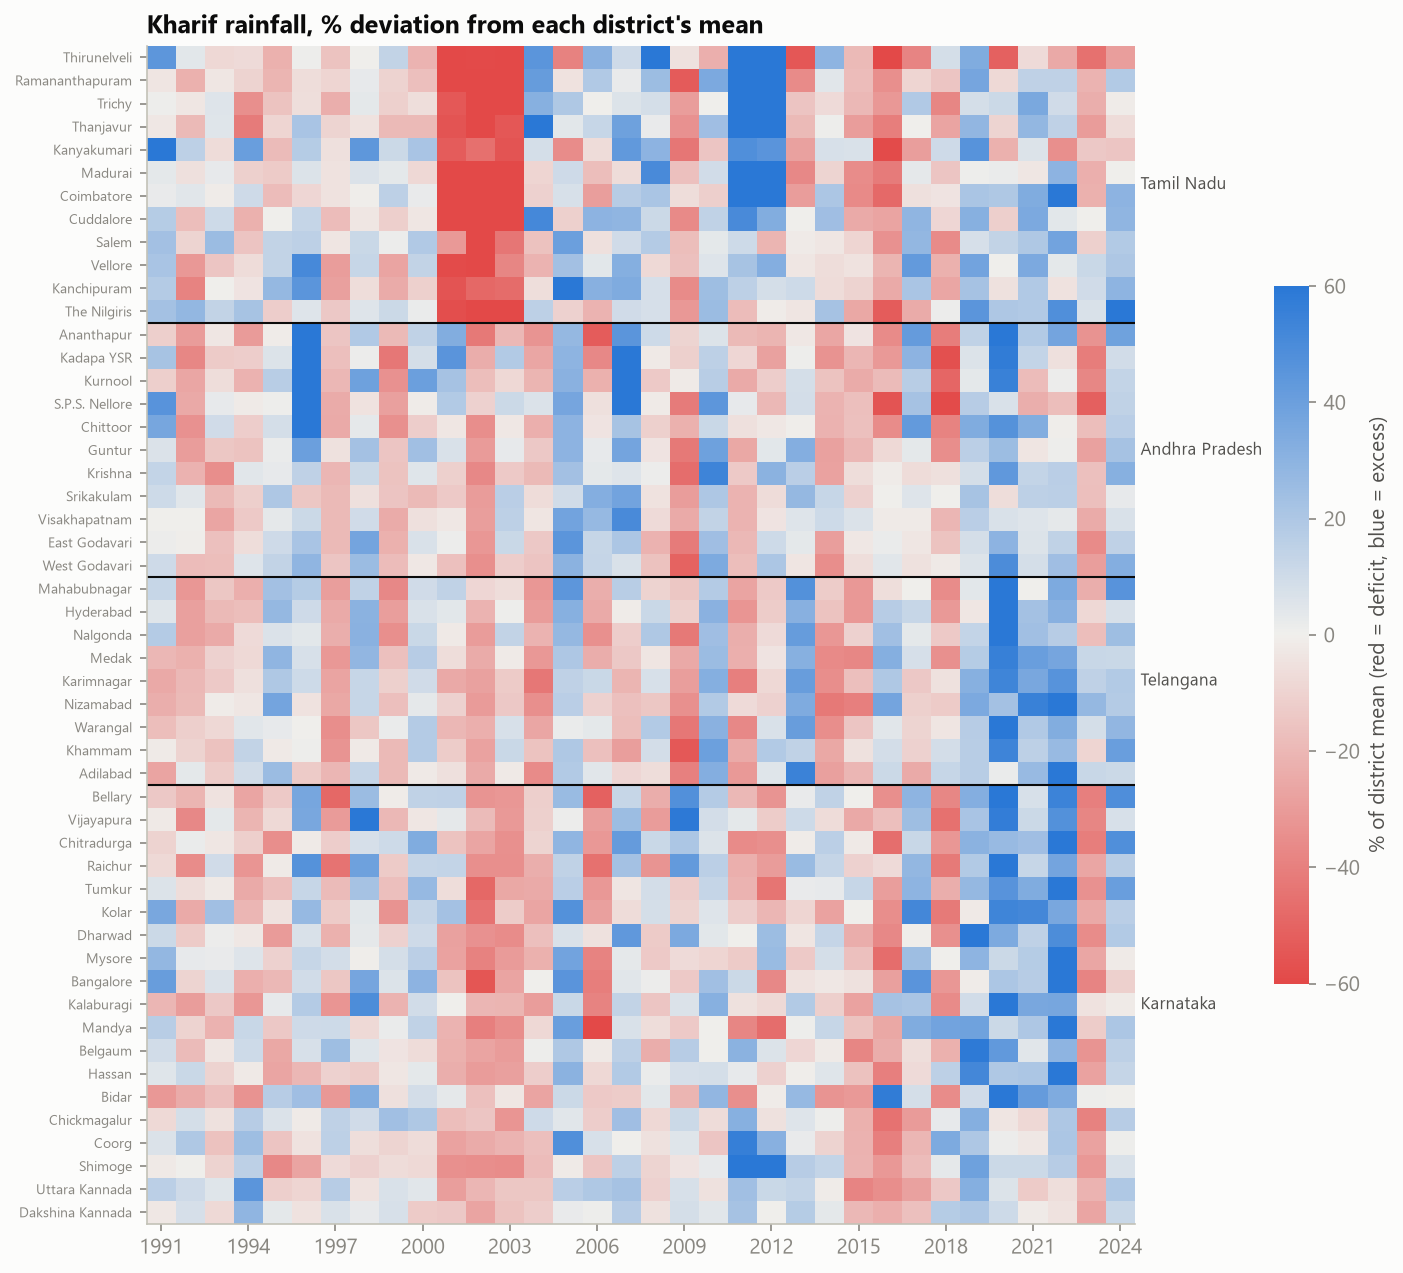

In [2]:
display(Image(filename=str(ROOT / 'reports' / 'figures' / 'rainfall_anomaly_heatmap.png')))

## Kharif rainfall variability (CV)

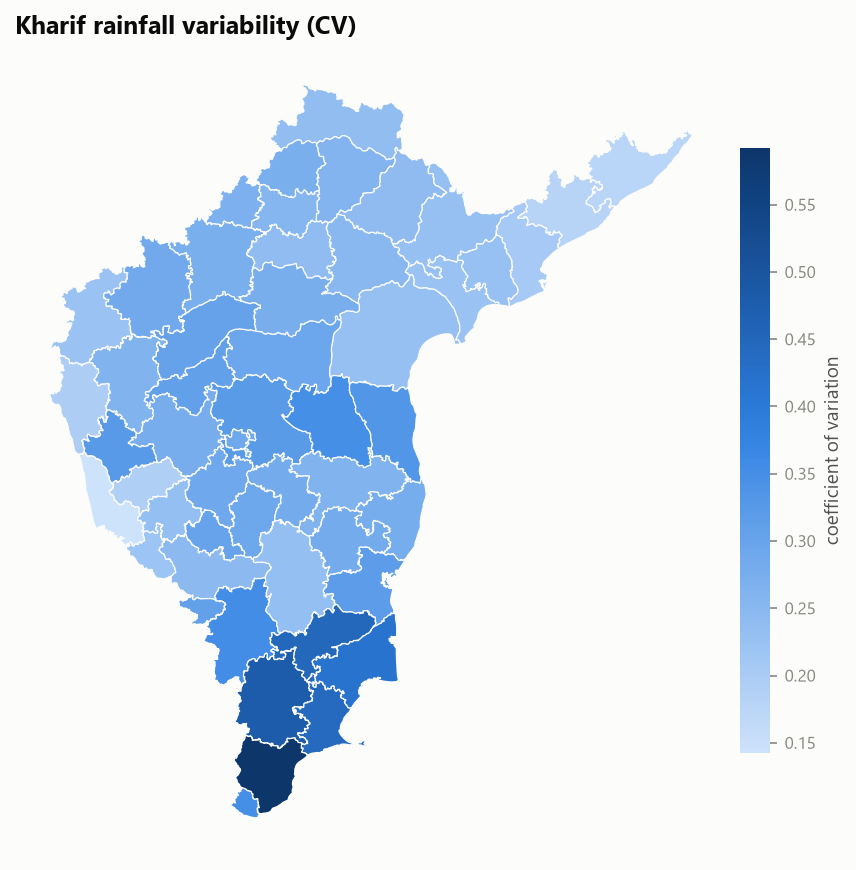

In [3]:
display(Image(filename=str(ROOT / 'reports' / 'figures' / 'rainfall_cv_kharif.png')))

## State yield trends with Theil-Sen fits

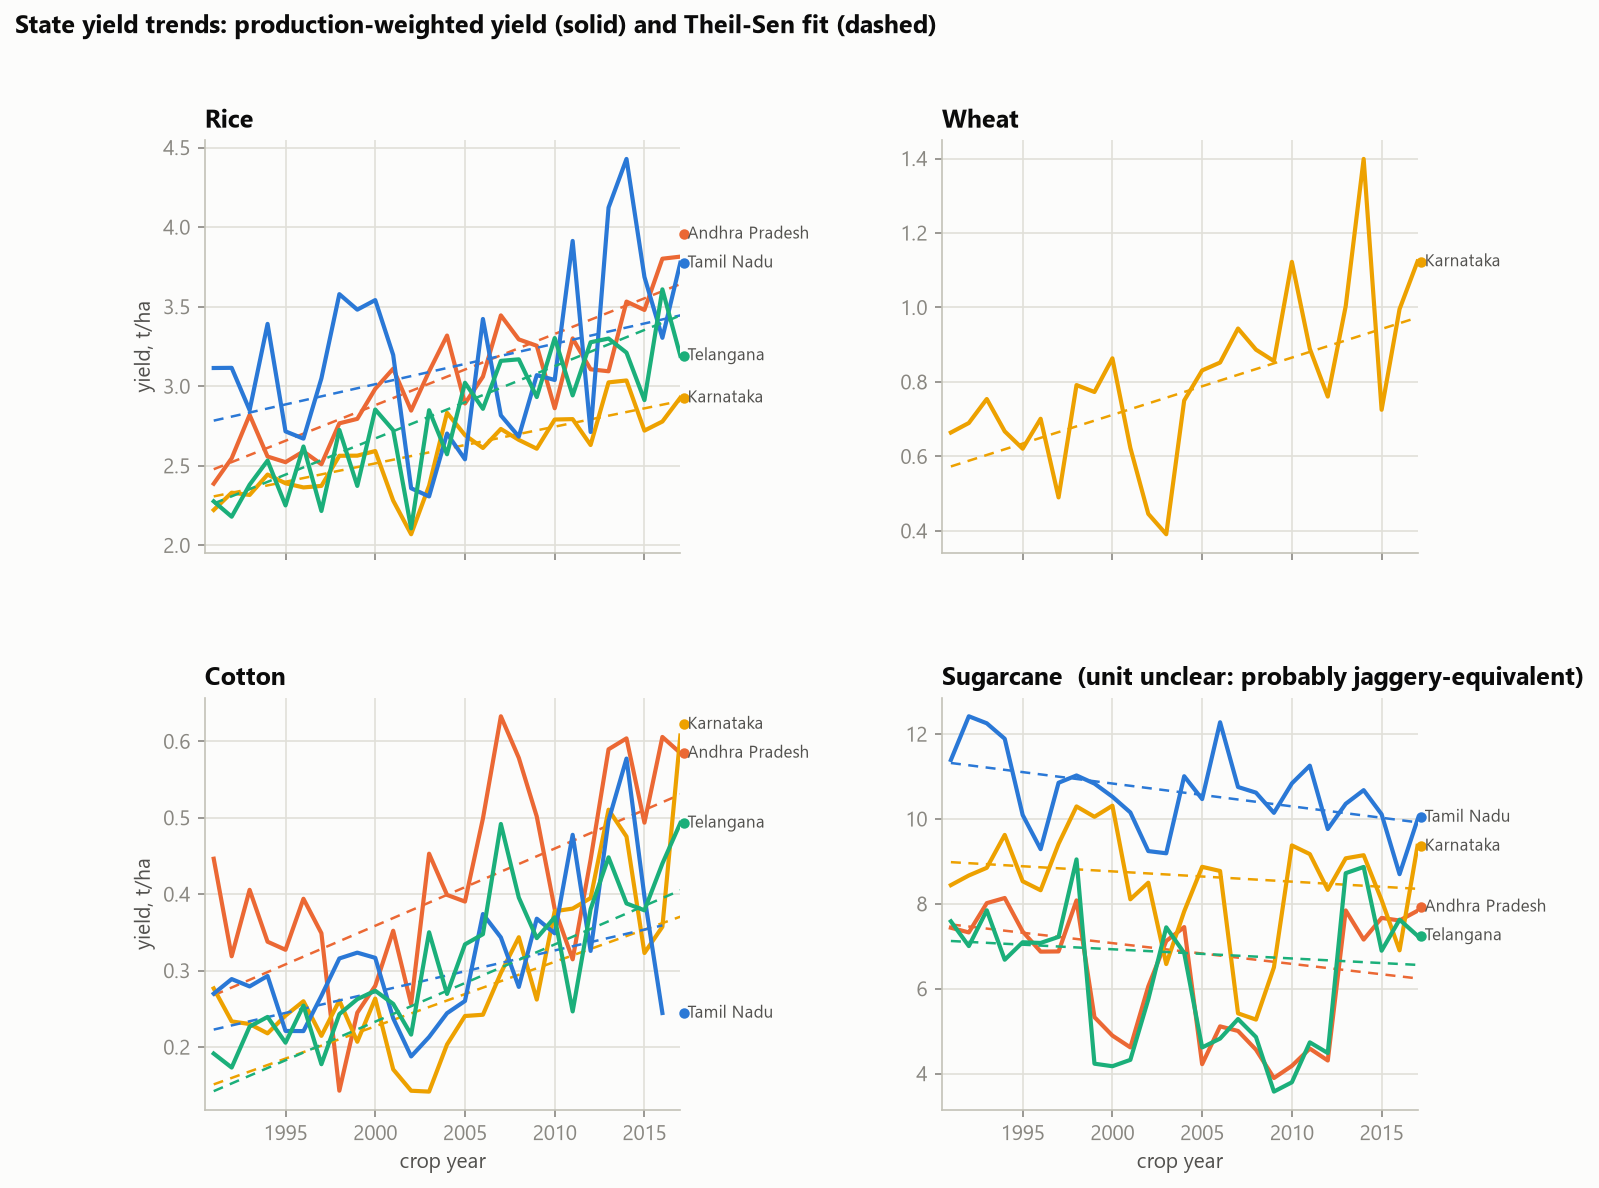

In [4]:
display(Image(filename=str(ROOT / 'reports' / 'figures' / 'yield_trends.png')))

## Drought and flood-risk frequency

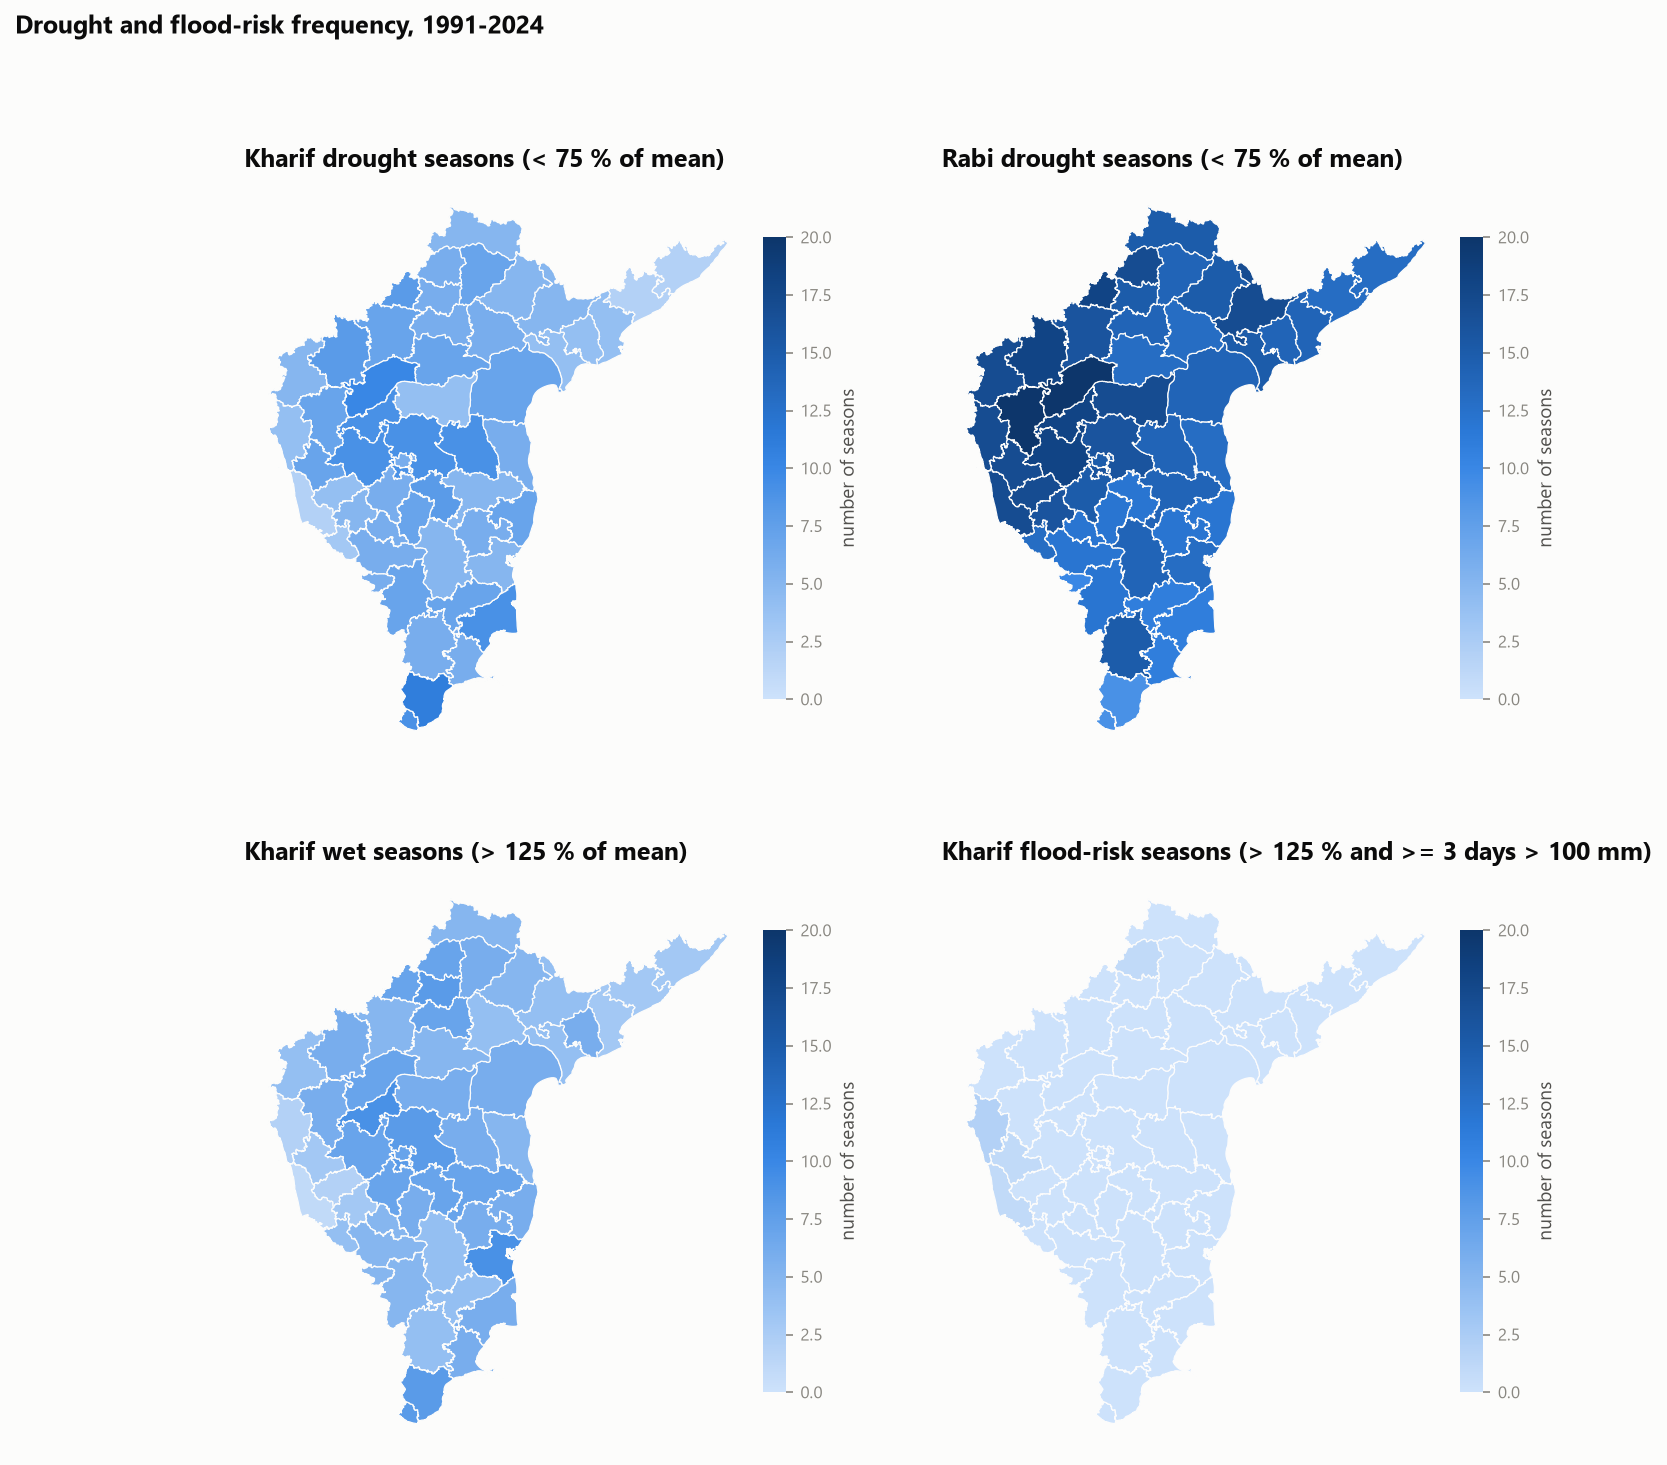

In [5]:
display(Image(filename=str(ROOT / 'reports' / 'figures' / 'drought_flood_frequency.png')))

## Within-district weather-yield correlations

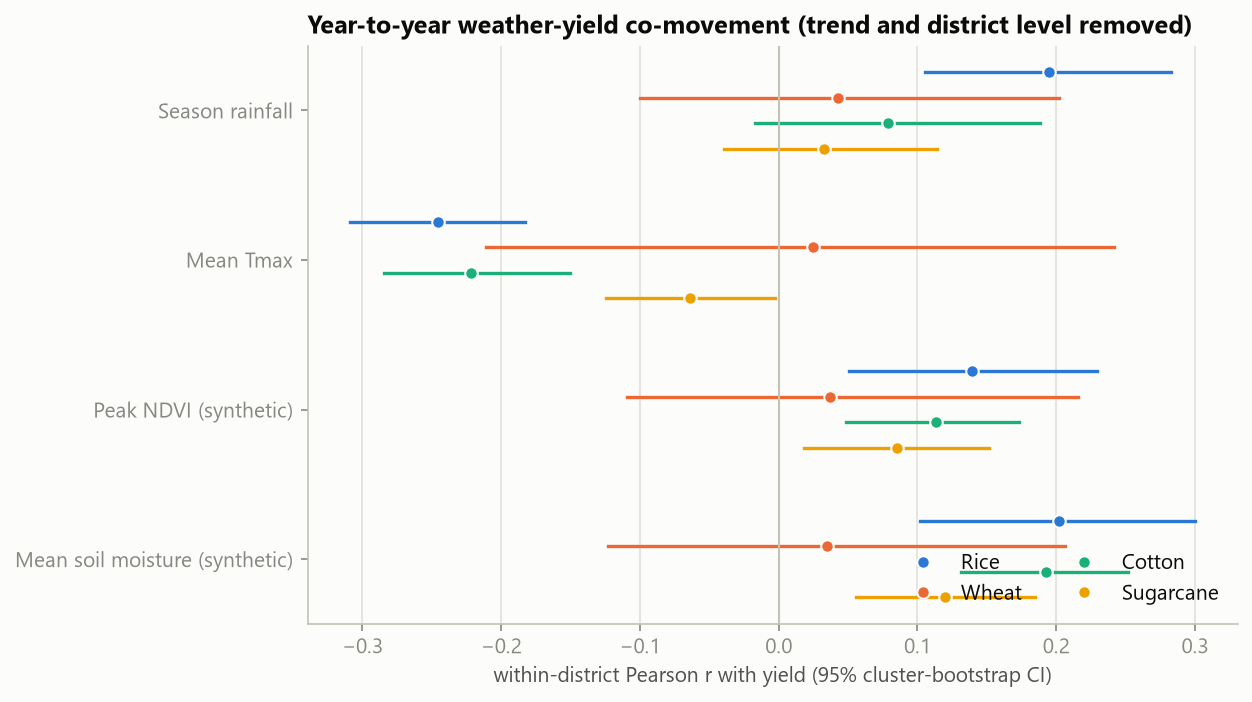

In [6]:
display(Image(filename=str(ROOT / 'reports' / 'figures' / 'correlations_within.png')))

## Fixed-effects regression residuals

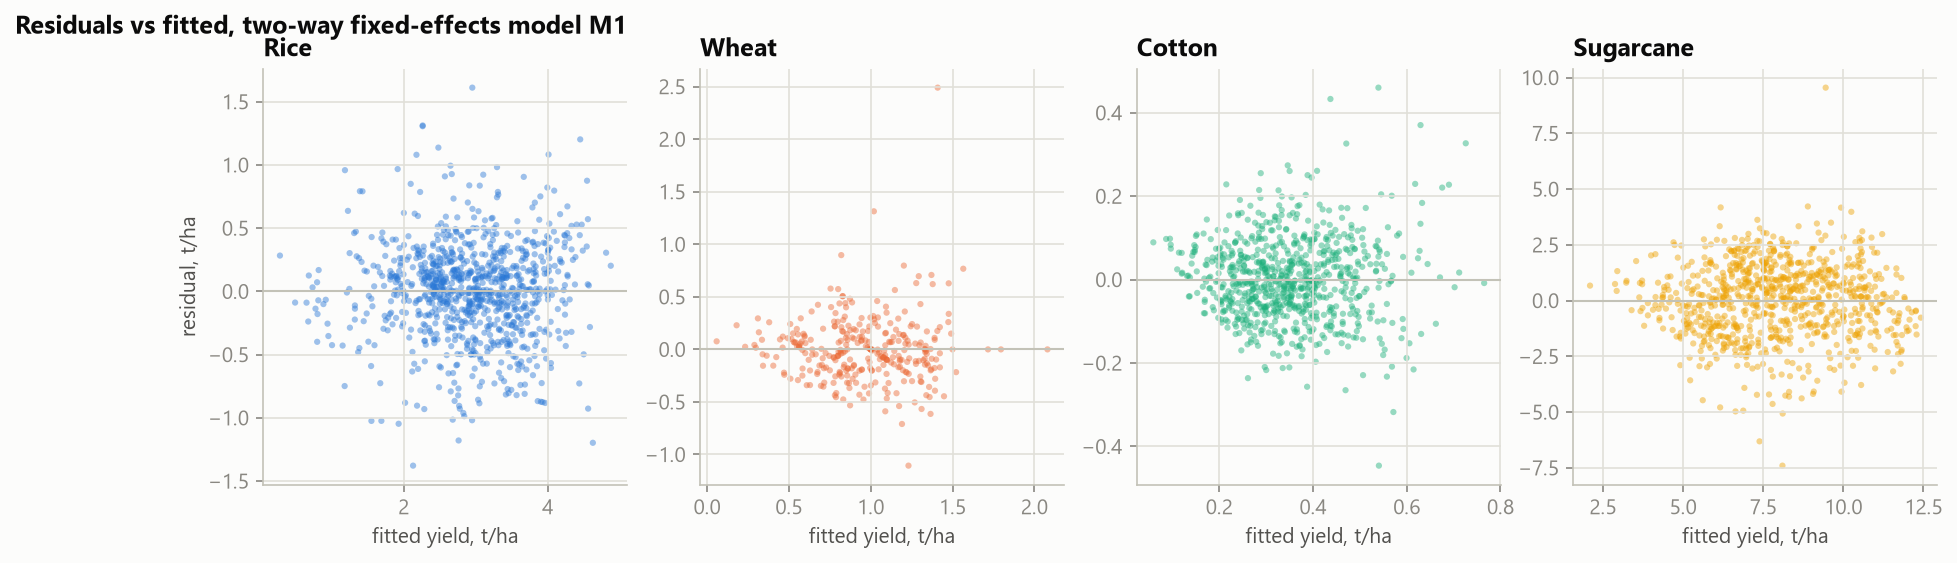

In [7]:
display(Image(filename=str(ROOT / 'reports' / 'figures' / 'regression_residuals.png')))

## Climate-vulnerability clusters

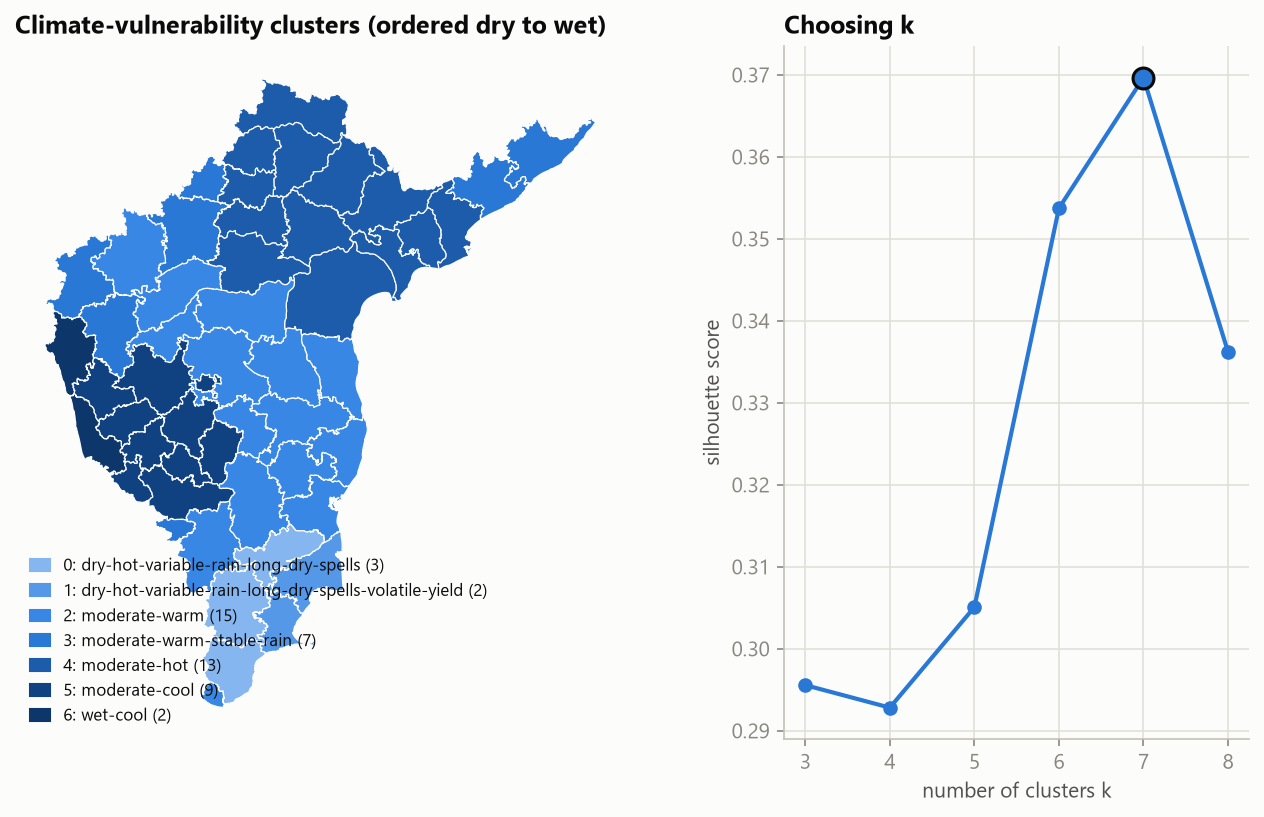

In [8]:
display(Image(filename=str(ROOT / 'reports' / 'figures' / 'clusters_map.png')))

## Yield trends (Theil-Sen, Mann-Kendall)

In [9]:
pd.read_csv(ROOT / 'reports' / 'analytics' / 'yield_trends_table.csv').round(4)

,state,crop,n_years,n_districts,mean_yield_t_ha,slope_t_ha_per_year,slope_ci_lo,slope_ci_hi,slope_pct_of_mean_per_year,mk_tau,mk_p,mk_trend
0,Andhra Pradesh,rice,27,11,3.0291,0.0448,0.0330,0.0549,1.4776,0.7037,0.0000,increasing
1,Andhra Pradesh,cotton,27,8,0.4195,0.0101,0.0042,0.0153,2.4077,0.4245,0.0020,increasing
2,Andhra Pradesh,sugarcane,27,8,6.2808,-0.0489,-0.1647,0.0154,-0.7789,-0.1852,0.1821,no trend
3,Karnataka,rice,27,19,2.5826,0.0231,0.0184,0.0314,0.8931,0.6353,0.0000,increasing
4,Karnataka,wheat,27,7,0.8005,0.0154,0.0083,0.0221,1.9222,0.5043,0.0002,increasing
5,Karnataka,cotton,27,13,0.2918,0.0084,0.0041,0.0134,2.8918,0.4758,0.0005,increasing
6,Karnataka,sugarcane,27,15,8.4381,-0.0242,-0.0815,0.0307,-0.2863,-0.1282,0.3590,no trend
7,Tamil Nadu,rice,27,12,3.1701,0.0254,-0.0072,0.0531,0.8026,0.2080,0.1334,no trend
8,Tamil Nadu,cotton,26,9,0.3143,0.0054,0.0024,0.0108,1.7338,0.3846,0.0063,increasing
9,Tamil Nadu,sugarcane,27,10,10.5974,-0.0538,-0.0970,-0.0100,-0.5074,-0.3390,0.0139,decreasing


## Fixed-effects regression coefficients

In [10]:
pd.read_csv(ROOT / 'reports' / 'analytics' / 'regression_coefficients.csv').round(4)

,crop,model,term,unit,coef,se_cluster,t,p,ci_lo,ci_hi,pct_of_mean_yield_per_1sd_within,vif_within,n,n_districts,r2,partial_r2_weather,synthetic_regressor
0,rice,M1_twoway_FE_weather,rain_100mm,per +100 mm season rainfall,0.0242,0.0073,3.3150,0.0009,0.0099,0.0386,1.9645,1.1369,918,51,0.8085,0.0057,False
1,rice,M1_twoway_FE_weather,tmax_c,per +1 C mean Tmax,-0.1068,0.0589,-1.8114,0.0701,-0.2223,0.0088,-1.8738,1.1369,918,51,0.8085,0.0057,False
2,rice,M2_twoway_FE_weather_satellite,rain_100mm,per +100 mm season rainfall,0.0200,0.0085,2.3629,0.0181,0.0034,0.0366,1.6193,1.4680,918,51,0.8098,0.0069,False
3,rice,M2_twoway_FE_weather_satellite,tmax_c,per +1 C mean Tmax,-0.0729,0.0661,-1.1030,0.2700,-0.2024,0.0566,-1.2795,1.2271,918,51,0.8098,0.0069,False
4,rice,M2_twoway_FE_weather_satellite,ndvi_01,per +0.1 peak NDVI,-0.0405,0.0372,-1.0880,0.2766,-0.1133,0.0324,-0.8832,1.7398,918,51,0.8098,0.0069,True
5,rice,M2_twoway_FE_weather_satellite,soilm_01,per +0.1 m3/m3 soil moisture,0.1181,0.0638,1.8517,0.0641,-0.0069,0.2431,1.7968,2.0051,918,51,0.8098,0.0069,True
6,rice,M3_district_FE_trend_weather,rain_100mm,per +100 mm season rainfall,0.0217,0.0074,2.9426,0.0033,0.0072,0.0361,1.7552,1.2050,918,51,0.7872,0.0143,False
7,rice,M3_district_FE_trend_weather,tmax_c,per +1 C mean Tmax,-0.1473,0.0248,-5.9445,0.0000,-0.1959,-0.0988,-2.5860,1.2050,918,51,0.7872,0.0143,False
8,wheat,M1_twoway_FE_weather,rain_100mm,per +100 mm season rainfall,-0.0368,0.1022,-0.3599,0.7189,-0.2372,0.1636,-1.6442,1.1856,315,30,0.4940,0.0060,False
9,wheat,M1_twoway_FE_weather,tmax_c,per +1 C mean Tmax,0.1446,0.1573,0.9197,0.3577,-0.1636,0.4528,7.4821,1.1856,315,30,0.4940,0.0060,False


## Cluster profiles (centroids in original units)

In [11]:
pd.read_csv(ROOT / 'reports' / 'analytics' / 'cluster_profiles.csv').round(4)

,cluster_id,cluster_label,n_districts,mean_rain_mm,rain_cv,mean_tmax_c,heat_days,dry_spell_days,yield_cv
0,0,dry-hot-variable-rain-long-dry-spells,3,431.1296,0.5138,32.8509,0.0000,33.0794,0.1118
1,1,dry-hot-variable-rain-long-dry-spells-volatile...,2,455.8810,0.4655,34.1216,0.0000,29.4048,0.3442
2,2,moderate-warm,15,544.8167,0.3110,32.3841,0.5333,22.9206,0.1175
3,3,moderate-warm-stable-rain,7,746.2631,0.2271,30.6013,0.7755,14.9184,0.2465
4,4,moderate-hot,13,833.9122,0.2265,32.6947,4.1538,15.9158,0.1116
5,5,moderate-cool,9,880.3625,0.2258,28.0703,-0.0000,16.0582,0.0799
6,6,wet-cool,2,3154.7606,0.1512,28.3308,0.0000,9.5714,0.1036
